#Exploring SOHO Images for Education Use
The  Solar and Heliospheric Observatory ([SOHO](https://soho.nascom.nasa.gov/)) Mission has a mandate to make the data collected publically avilable.  One way to acces this data is the the SunPy library

This notebook provide examples that access and display differet SOHO imagery for use in both research and educational settings. These cells can be used as part of more complete activities outlined in other notebooks in this repository that also use Solar Dynamics Observatory ([SDO]((https://sdo.gsfc.nasa.gov)))

The Google AI Gemini was used in the create in of this Notebook

Notebook Author: Nicholas Gross (gross@bu.edu)

### Retrieving SOHO/EIT EUV Images from May 8th, 2002
In 2002 (during Solar Cycle 23's maximum), the primary solar EUV imager was **SOHO/EIT**. We will fetch data from three of its primary channels: **171 Å** (quiet corona), **195 Å** (active corona), and **304 Å** (chromosphere/transition region) to compare against the 2024 SDO/AIA images.

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Searching and fetching EIT 171 Å...
Searching and fetching EIT 195 Å...
Searching and fetching EIT 284 Å...
Searching and fetching EIT 304 Å...


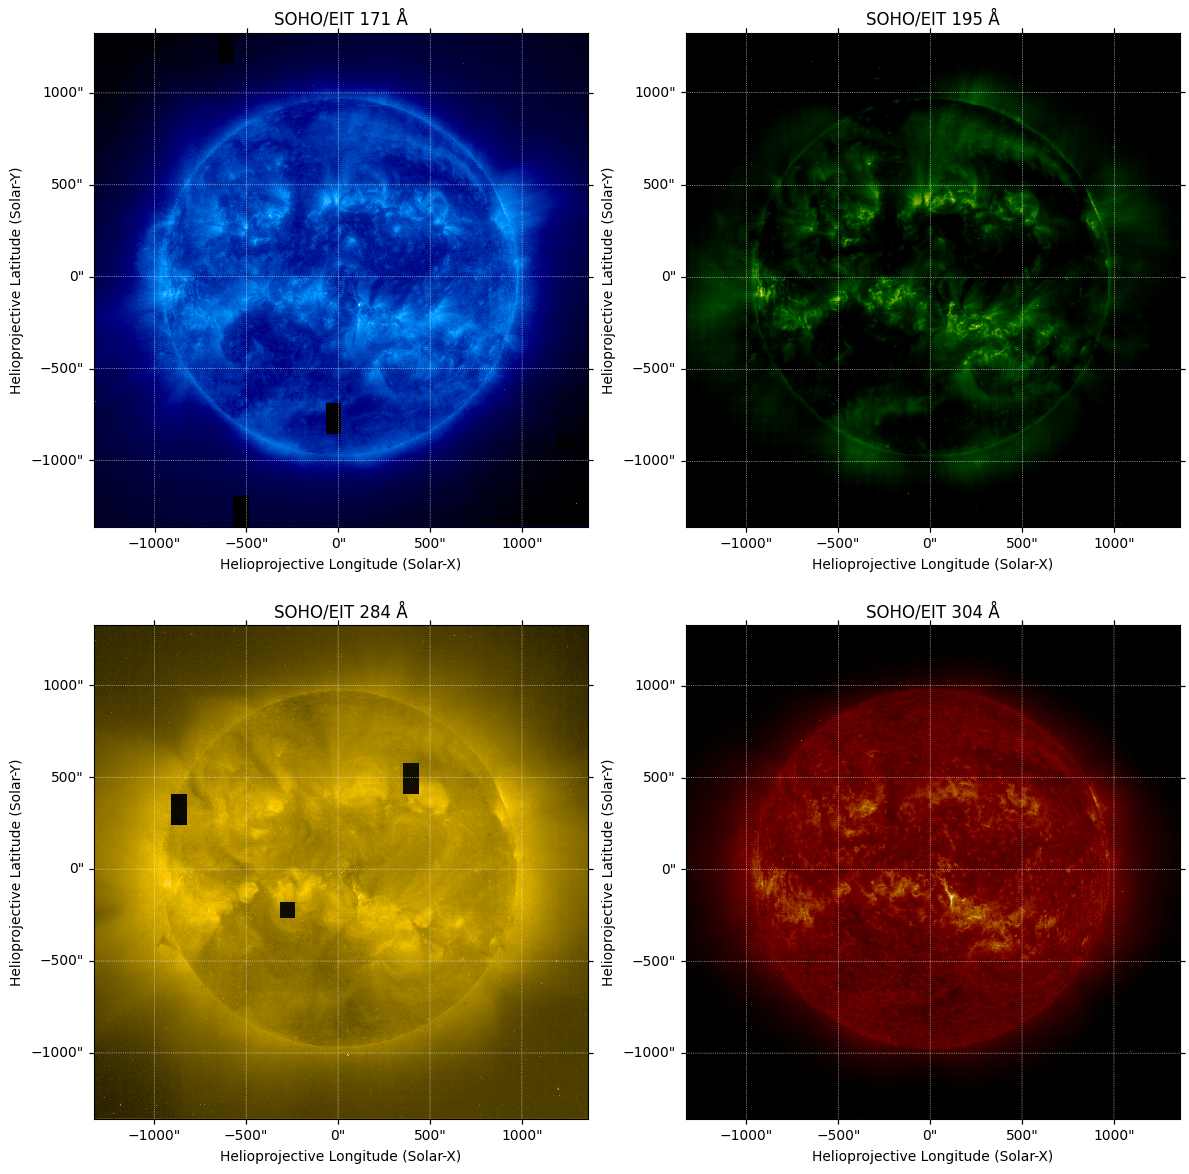

In [1]:
%pip install -q "sunpy[all]" astropy

import pathlib
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.time import Time
from astropy.visualization import ImageNormalize, AsinhStretch
import sunpy
import sunpy.map
from sunpy.net import Fido, attrs as a

# Ensure DATA_DIR is defined
DATA_DIR = pathlib.Path('./data')
DATA_DIR.mkdir(exist_ok=True)

time_start_2002 = Time('2002-05-08 12:00:00')

# 1. Fetch and load all four SOHO/EIT maps (171, 195, 284, 304 Å)
print("Searching and fetching EIT 171 Å...")
q_eit_1 = Fido.search(
    a.Time(time_start_2002 - 2*u.hour, time_start_2002 + 2*u.hour, near=time_start_2002),
    a.Instrument.eit,
    a.Wavelength(171*u.AA)
)
file_eit_1 = Fido.fetch(q_eit_1[0, 0] if q_eit_1 else None, path=DATA_DIR / 'EIT' / '{file}', progress=False)
map_eit_1 = sunpy.map.Map(file_eit_1)

print("Searching and fetching EIT 195 Å...")
q_eit_2 = Fido.search(
    a.Time(time_start_2002 - 2*u.hour, time_start_2002 + 2*u.hour, near=time_start_2002),
    a.Instrument.eit,
    a.Wavelength(195*u.AA)
)
file_eit_2 = Fido.fetch(q_eit_2[0, 0] if q_eit_2 else None, path=DATA_DIR / 'EIT' / '{file}', progress=False)
map_eit_2 = sunpy.map.Map(file_eit_2)

print("Searching and fetching EIT 284 Å...")
q_eit_4 = Fido.search(
    a.Time(time_start_2002 - 2*u.hour, time_start_2002 + 2*u.hour, near=time_start_2002),
    a.Instrument.eit,
    a.Wavelength(284*u.AA)
)
file_eit_4 = Fido.fetch(q_eit_4[0, 0] if q_eit_4 else None, path=DATA_DIR / 'EIT' / '{file}', progress=False)
map_eit_4 = sunpy.map.Map(file_eit_4)

print("Searching and fetching EIT 304 Å...")
q_eit_3 = Fido.search(
    a.Time(time_start_2002 - 2*u.hour, time_start_2002 + 2*u.hour, near=time_start_2002),
    a.Instrument.eit,
    a.Wavelength(304*u.AA)
)
file_eit_3 = Fido.fetch(q_eit_3[0, 0] if q_eit_3 else None, path=DATA_DIR / 'EIT' / '{file}', progress=False)
map_eit_3 = sunpy.map.Map(file_eit_3)

# 2. Create an updated 2x2 grid plot of the four channels (171, 195, 284, 304 Å)
fig = plt.figure(figsize=(12, 12))

# Top-Left: 171 Å
ax1 = fig.add_subplot(2, 2, 1, projection=map_eit_1)
map_eit_1.plot(axes=ax1)
ax1.coords.grid(grid_type='contours', color='white', alpha=0.5)
ax1.set_title('SOHO/EIT 171 Å')

# Top-Right: 195 Å
ax2 = fig.add_subplot(2, 2, 2, projection=map_eit_2)
map_eit_2.plot(axes=ax2)
ax2.coords.grid(grid_type='contours', color='white', alpha=0.5)
ax2.set_title('SOHO/EIT 195 Å')

# Bottom-Left: 284 Å
ax3 = fig.add_subplot(2, 2, 3, projection=map_eit_4)
map_eit_4.plot(axes=ax3)
ax3.coords.grid(grid_type='contours', color='white', alpha=0.5)
ax3.set_title('SOHO/EIT 284 Å')

# Bottom-Right: 304 Å
ax4 = fig.add_subplot(2, 2, 4, projection=map_eit_3)
map_eit_3.plot(axes=ax4)
ax4.coords.grid(grid_type='contours', color='white', alpha=0.5)
ax4.set_title('SOHO/EIT 304 Å')

plt.tight_layout()
plt.show()

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

mdi_fd_M_lev182_4917021_4917021.tar: 0.00B [00:00, ?B/s]

Files Downloaded:   0%|          | 0/1 [00:00<?, ?file/s]

mdi_fd_Ic_4917024_4917024.tar: 0.00B [00:00, ?B/s]

/tmp/ipykernel_1233/1922595624.py:30: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


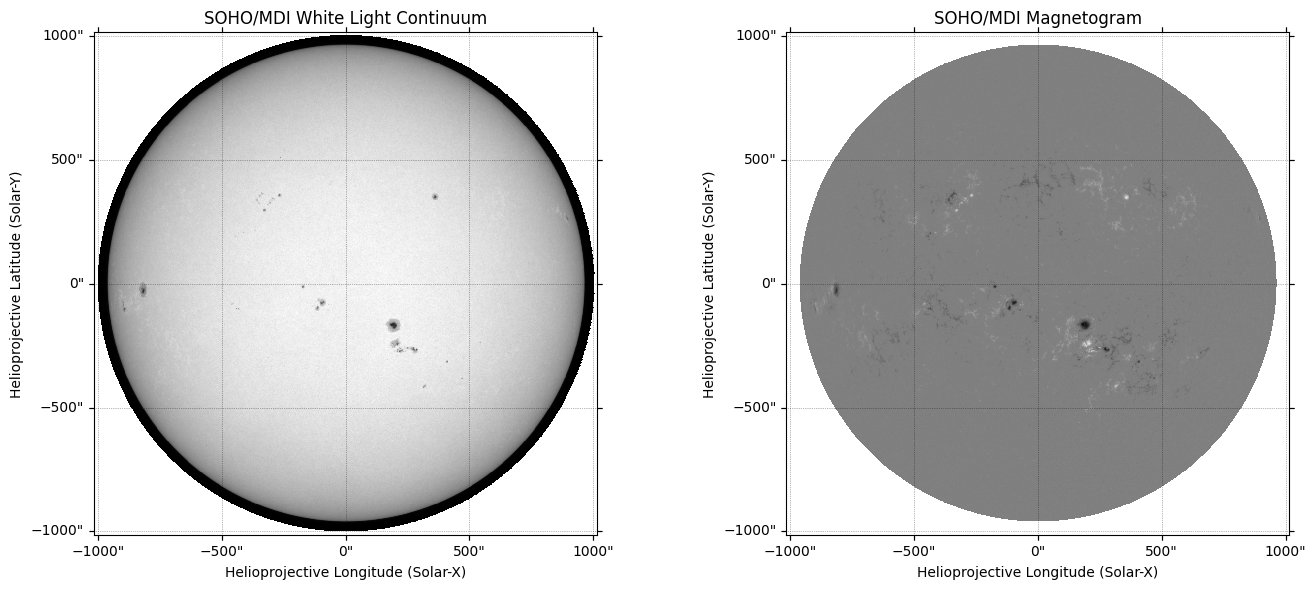

In [2]:
import tarfile

# 1. Search for SOHO/MDI Magnetogram and Continuum (White Light) data for May 8th, 2002
time_start_2002 = Time('2002-05-08 12:00:00')

# Query MDI Magnetogram
q_mdi_mag = Fido.search(
    a.Time(time_start_2002 - 4*u.hour, time_start_2002 + 4*u.hour, near=time_start_2002),
    a.Instrument.mdi,
    a.Physobs.los_magnetic_field
)

# Query MDI Continuum (White Light)
q_mdi_cont = Fido.search(
    a.Time(time_start_2002 - 4*u.hour, time_start_2002 + 4*u.hour, near=time_start_2002),
    a.Instrument.mdi,
    a.Physobs.intensity
)

# Fetch the tar files
file_mdi_mag = Fido.fetch(q_mdi_mag[0, 0] if q_mdi_mag else None, path=DATA_DIR / 'MDI' / '{file}')
file_mdi_cont = Fido.fetch(q_mdi_cont[0, 0] if q_mdi_cont else None, path=DATA_DIR / 'MDI' / '{file}')

# Helper function to extract .tar files and return the path of the extracted FITS file
def extract_fits_from_tar(tar_path):
    path = pathlib.Path(tar_path)
    extract_dir = path.parent / path.stem
    extract_dir.mkdir(parents=True, exist_ok=True)
    with tarfile.open(path) as tar:
        tar.extractall(path=extract_dir)
    # Find first fits file inside the extracted directory
    fits_files = list(extract_dir.glob('**/*.fits')) + list(extract_dir.glob('**/*.fit')) + list(extract_dir.glob('*'))
    # Return the first file that is not a directory
    for f in fits_files:
        if f.is_file():
            return f
    return path

# Extract FITS files
fits_mdi_mag = extract_fits_from_tar(file_mdi_mag[0])
fits_mdi_cont = extract_fits_from_tar(file_mdi_cont[0])

map_mdi_mag = sunpy.map.Map(fits_mdi_mag)
map_mdi_cont = sunpy.map.Map(fits_mdi_cont)

# 2. Display side-by-side plots (Swapped: Continuum on left, Magnetogram on right)
fig = plt.figure(figsize=(14, 6))

# Left panel: MDI Continuum (White Light)
ax1 = fig.add_subplot(1, 2, 1, projection=map_mdi_cont)
map_mdi_cont.plot(axes=ax1, cmap='gray')
ax1.coords.grid(grid_type='contours', color='black', alpha=0.3)
ax1.set_title('SOHO/MDI White Light Continuum')

# Right panel: MDI Magnetogram
ax2 = fig.add_subplot(1, 2, 2, projection=map_mdi_mag)
map_mdi_mag.plot(axes=ax2, cmap='gray')
ax2.coords.grid(grid_type='contours', color='black', alpha=0.3)
ax2.set_title('SOHO/MDI Magnetogram')

plt.tight_layout()
plt.show()

### Visualizing Solar Cycle 23 Progression: SOHO/MDI (1996 - 2010)
Below, we fetch and display side-by-side magnetograms and white light continuum images for each year from 1996 to 2010 to observe the rise, peak, and fall of Solar Cycle 23.

In [3]:
%pip install -q "sunpy[all]" astropy

import tarfile
import pathlib
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.time import Time
import sunpy.map
from sunpy.net import Fido, attrs as a

# Use existing DATA_DIR or define it
DATA_DIR = pathlib.Path('./data')
DATA_DIR.mkdir(exist_ok=True)

def extract_fits_from_tar(tar_path):
    path = pathlib.Path(tar_path)
    extract_dir = path.parent / path.stem
    extract_dir.mkdir(parents=True, exist_ok=True)
    with tarfile.open(path) as tar:
        tar.extractall(path=extract_dir)
    fits_files = list(extract_dir.glob('**/*.fits')) + list(extract_dir.glob('**/*.fit')) + list(extract_dir.glob('*'))
    for f in fits_files:
        if f.is_file():
            return f
    return path

# We will select May 8th of each year from 1996 to 2010
for year in range(1996, 2011):
    print(f"--- Fetching and Processing Data for Year: {year} ---")
    target_time = Time(f"{year}-05-08 12:00:00")

    # Query Magnetogram and Continuum
    q_mag = Fido.search(
        a.Time(target_time - 12*u.hour, target_time + 12*u.hour, near=target_time),
        a.Instrument.mdi,
        a.Physobs.los_magnetic_field
    )

    q_cont = Fido.search(
        a.Time(target_time - 12*u.hour, target_time + 12*u.hour, near=target_time),
        a.Instrument.mdi,
        a.Physobs.intensity
    )

    if not q_mag or not q_cont:
        print(f"Data not available for {year}-05-08, skipping.")
        continue

    try:
        # Fetch tar files
        file_mag = Fido.fetch(q_mag[0, 0], path=DATA_DIR / f'MDI_{year}' / '{file}', progress=False)
        file_cont = Fido.fetch(q_cont[0, 0], path=DATA_DIR / f'MDI_{year}' / '{file}', progress=False)

        # Extract FITS
        fits_mag = extract_fits_from_tar(file_mag[0])
        fits_cont = extract_fits_from_tar(file_cont[0])

        # Load Maps
        map_mag = sunpy.map.Map(fits_mag)
        map_cont = sunpy.map.Map(fits_cont)

        # Plot Side-by-Side (Swapped: Continuum on left, Magnetogram on right)
        fig = plt.figure(figsize=(12, 5))

        # Left: Continuum
        ax1 = fig.add_subplot(1, 2, 1, projection=map_cont)
        map_cont.plot(axes=ax1, cmap='gray')
        ax1.coords.grid(grid_type='contours', color='black', alpha=0.3)
        ax1.set_title(f'SOHO/MDI White Light - {year}')

        # Right: Magnetogram
        ax2 = fig.add_subplot(1, 2, 2, projection=map_mag)
        map_mag.plot(axes=ax2, cmap='gray')
        ax2.coords.grid(grid_type='contours', color='black', alpha=0.3)
        ax2.set_title(f'SOHO/MDI Magnetogram - {year}')

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"An error occurred while processing year {year}: {e}")

Output hidden; open in https://colab.research.google.com to view.

### Visualizing Solar Cycle 23 Progression: SOHO/EIT (1996 - 2010)
Below, we fetch and display side-by-side SOHO/EIT EUV maps for the **171 Å** (quiet corona) and **284 Å** (active region corona) wavelengths for each year from 1996 through 2010.

In [4]:
# We will select May 8th of each year from 1996 to 2010 for EIT 171 and 284
for year in range(1996, 2011):
    print(f"--- Fetching and Processing EIT Data for Year: {year} ---")
    target_time = Time(f"{year}-05-08 12:00:00")

    # Query EIT 171
    q_eit_171 = Fido.search(
        a.Time(target_time - 12*u.hour, target_time + 12*u.hour, near=target_time),
        a.Instrument.eit,
        a.Wavelength(171*u.AA)
    )

    # Query EIT 284
    q_eit_284 = Fido.search(
        a.Time(target_time - 12*u.hour, target_time + 12*u.hour, near=target_time),
        a.Instrument.eit,
        a.Wavelength(284*u.AA)
    )

    if not q_eit_171 or not q_eit_284:
        print(f"Data not available for {year}-05-08, skipping.")
        continue

    try:
        # Fetch files
        file_eit_171 = Fido.fetch(q_eit_171[0, 0], path=DATA_DIR / f'EIT_{year}' / '{file}', progress=False)
        file_eit_284 = Fido.fetch(q_eit_284[0, 0], path=DATA_DIR / f'EIT_{year}' / '{file}', progress=False)

        # Load Maps
        map_eit_171 = sunpy.map.Map(file_eit_171)
        map_eit_284 = sunpy.map.Map(file_eit_284)

        # Plot Side-by-Side
        fig = plt.figure(figsize=(12, 5))

        # Left: EIT 171
        ax1 = fig.add_subplot(1, 2, 1, projection=map_eit_171)
        map_eit_171.plot(axes=ax1)
        ax1.coords.grid(grid_type='contours', color='white', alpha=0.5)
        ax1.set_title(f'SOHO/EIT 171 Å - {year}')

        # Right: EIT 284
        ax2 = fig.add_subplot(1, 2, 2, projection=map_eit_284)
        map_eit_284.plot(axes=ax2)
        ax2.coords.grid(grid_type='contours', color='white', alpha=0.5)
        ax2.set_title(f'SOHO/EIT 284 Å - {year}')

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"An error occurred while processing EIT data for year {year}: {e}")

Output hidden; open in https://colab.research.google.com to view.